In [2]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb
from my_helpers import plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_u_theta_mesh, plot_comparison_together


from minmax_opt_class_mgnn import MinMaxOptProb

In [3]:
def u0(x):
    return -jnp.sin(jnp.pi*x)

# Boundary at x=-1
def u1(x):
    return 0
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=2
def u2(x):
    return 0
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x


t_min = 0
t_max = 1
x_min = -1
x_max = 1

In [4]:
notes = '''This notebook is for computing Burgers equation with sin init, \n
featured with initial gamma = 0.1, f_opt_kh = 1, use_a = True, and L1reg = 0.1.\n
We use warmup_exponential_decay_schedule for the learning rate.\n
We use normal sampling to optimize k_h with sigma = 1.
In this copy, we train 5000 epoches. '''
print(notes)

This notebook is for computing Burgers equation with sin init, 

featured with initial gamma = 0.1, f_opt_kh = 1, use_a = True, and L1reg = 0.1.

We use warmup_exponential_decay_schedule for the learning rate.

We use normal sampling to optimize k_h with sigma = 1.
In this copy, we train 5000 epoches. 


In [4]:
N_t = 8
N_x = 17
seq_trainer = SeqMinMaxOptProb(
    num_segments=2,
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max,
    N_t=N_t, N_x=N_x, N_bc=2048, N_ic=4096, pre_epochs=0,
    hidden_dims_list=[[64, 64, 64, 64, 64]], seed=0,
    sigma=10, N_perturb=50000, k_h_rf_times=2, f_opt_kh=1,
    u0=u0, u1=vmap_u1, u2=vmap_u2, project="seq_minmax_burgers_sin_wave",
    gamma=0, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0, sampling_method='uniform', notes=notes,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[10000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, total_grade=1, k=0, f_plot=1000, plt_err_dist=True, plt_mesh=True, partition='rect',
    set_wandb=False
)


In [ ]:
seq_trainer.train_seq()

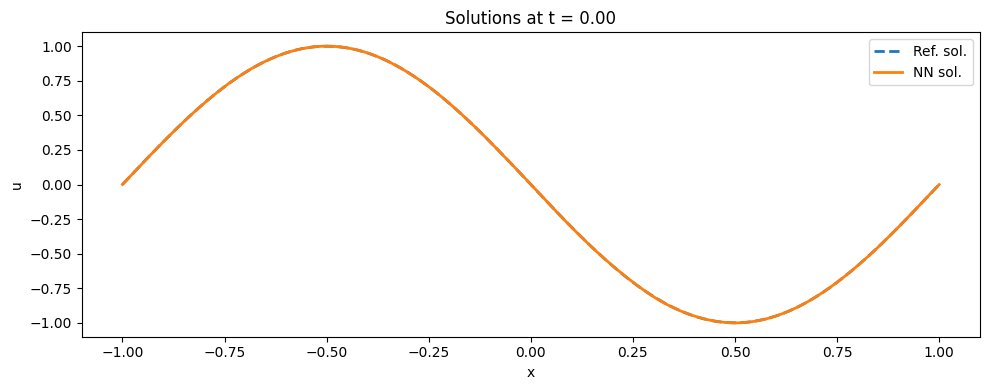

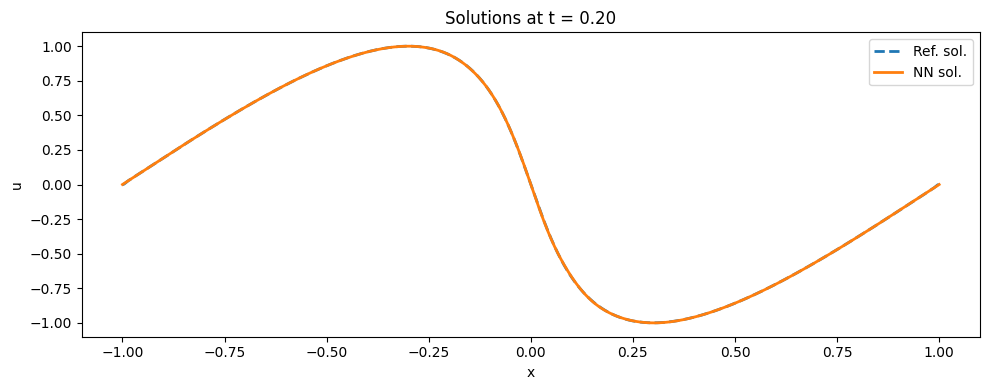

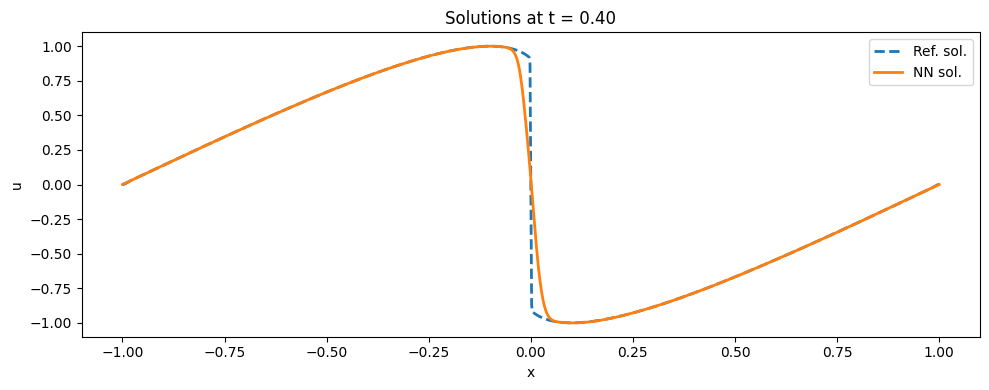

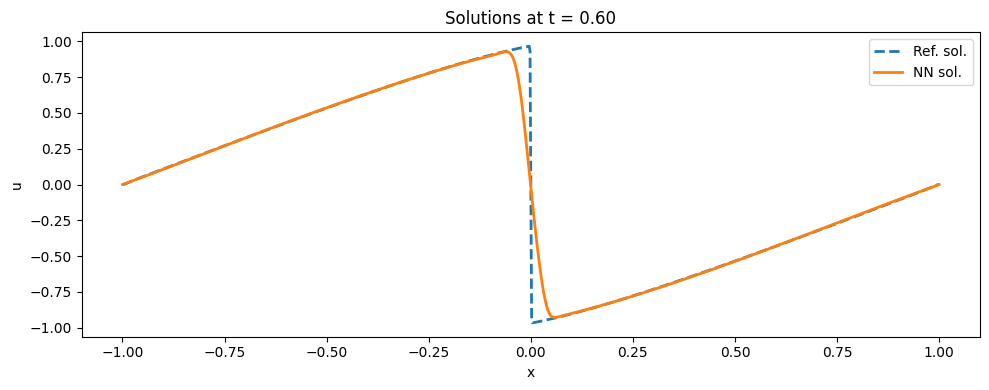

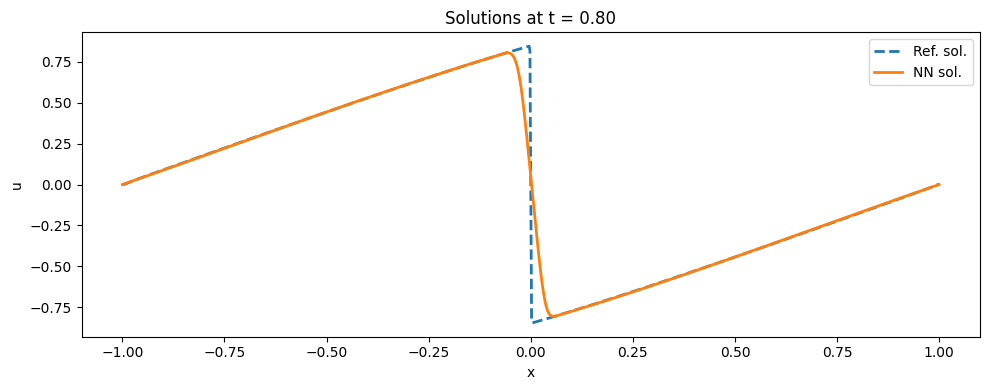

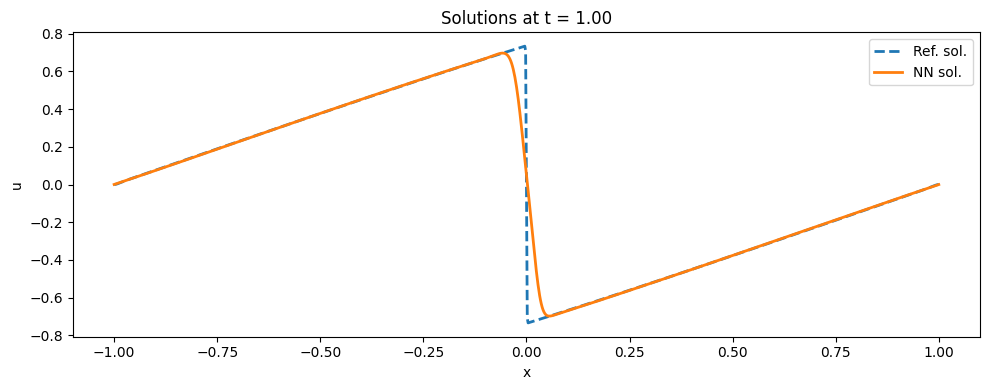

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


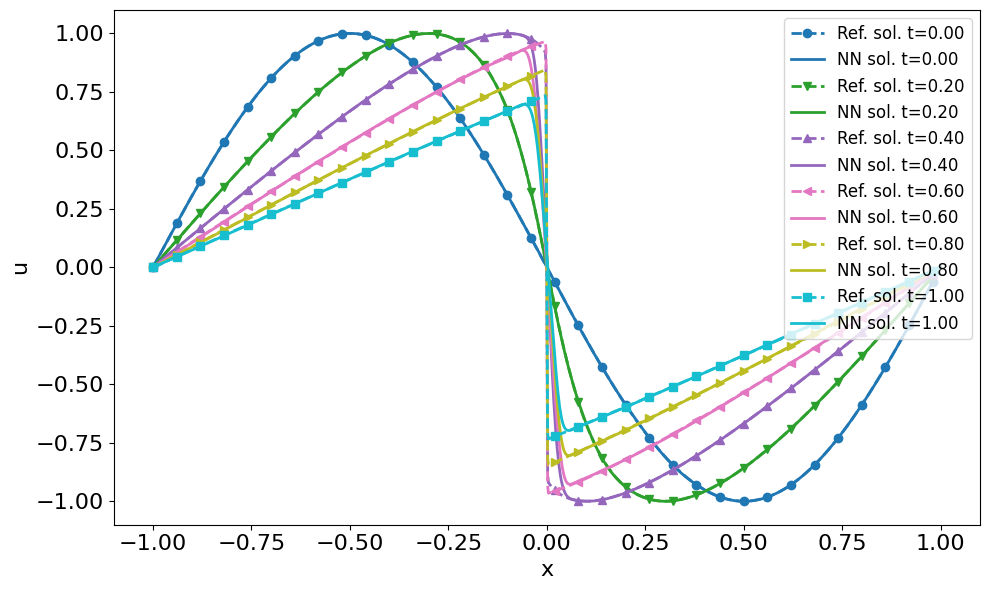

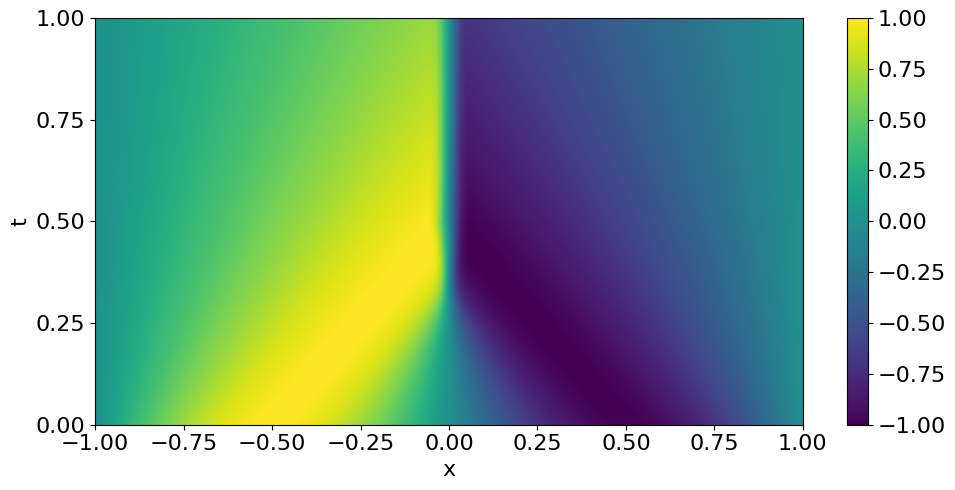

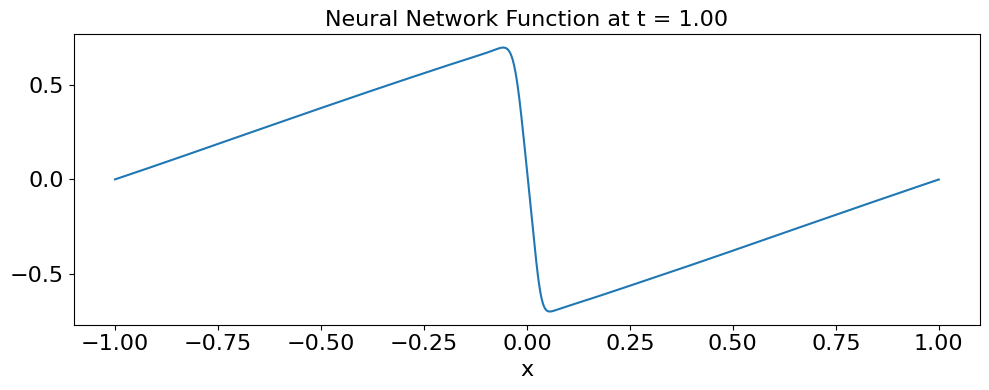

Error at T: 0.028156847324693663, Relative error at T: 0.037706760585481953
Space-time error: 0.02310886039457342, Space-time relative error: 0.02127746210947487


(np.float64(0.037706760585481953), np.float64(0.02127746210947487))

In [8]:

plot_comparison_seperate_combined_u_theta(seq_trainer, x_min=-1, x_max=1, ts=[0.2*i for i in range(6)])
plot_comparison_together(seq_trainer, save_path=f'../results/sin_wave_comparison_{N_t}_{N_x}.eps', x_min=-1, x_max=1, ts=[0.2*i for i in range(6)])
plot_u_theta(seq_trainer, save_path=f'../results/sin_wave_plot_{N_t}_{N_x}.eps')
compute_errors_combined_u_theta(seq_trainer, x_min=-1, x_max=1, T=1.0)

Adding grade 1 with hidden dims [64, 64, 64, 64]

Plotting before training segment [0.0000, 0.5000]


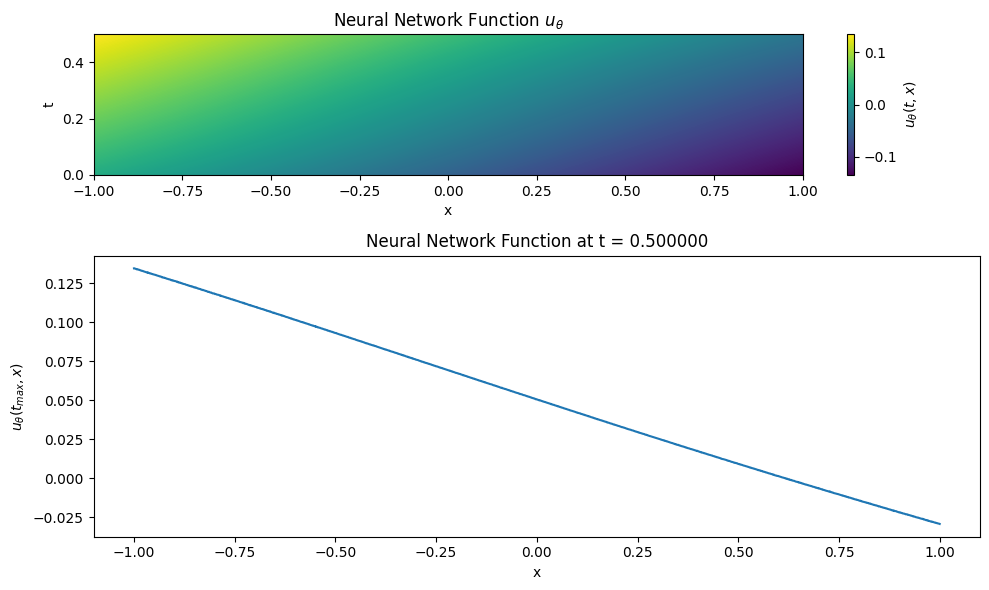


Training segment [0.0000, 0.5000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, loss_eqn: 0.204637, loss_eqn_from_kh: 0.204636, loss_eqn_abs: 0.204636, loss_ibc: 0.467140
Grade 0, Iter 100, loss_eqn: 0.536331, loss_eqn_from_kh: 0.536317, loss_eqn_abs: 0.536317, loss_ibc: 0.049528
Grade 0, Iter 200, loss_eqn: 0.372386, loss_eqn_from_kh: 0.372369, loss_eqn_abs: 0.372372, loss_ibc: 0.008679
Grade 0, Iter 300, loss_eqn: 0.247993, loss_eqn_from_kh: 0.247969, loss_eqn_abs: 0.247970, loss_ibc: 0.008688
Grade 0, Iter 400, loss_eqn: 0.196765, loss_eqn_from_kh: 0.196711, loss_eqn_abs: 0.196713, loss_ibc: 0.006674
Grade 0, Iter 500, loss_eqn: 0.139682, loss_eqn_from_kh: 0.139561, loss_eqn_abs: 0.139573, loss_ibc: 0.007157
Grade 0, Iter 600, loss_eqn: 0.129714, loss_eqn_from_kh: 0.129583, loss_eqn_abs: 0.129871, loss_ibc: 0.004383
Grade 0, Iter 700, loss_eqn: 0.131815, loss_eqn_from_kh: 0.131676, loss_eqn_abs: 0.131923, loss_ibc: 0.005072
G

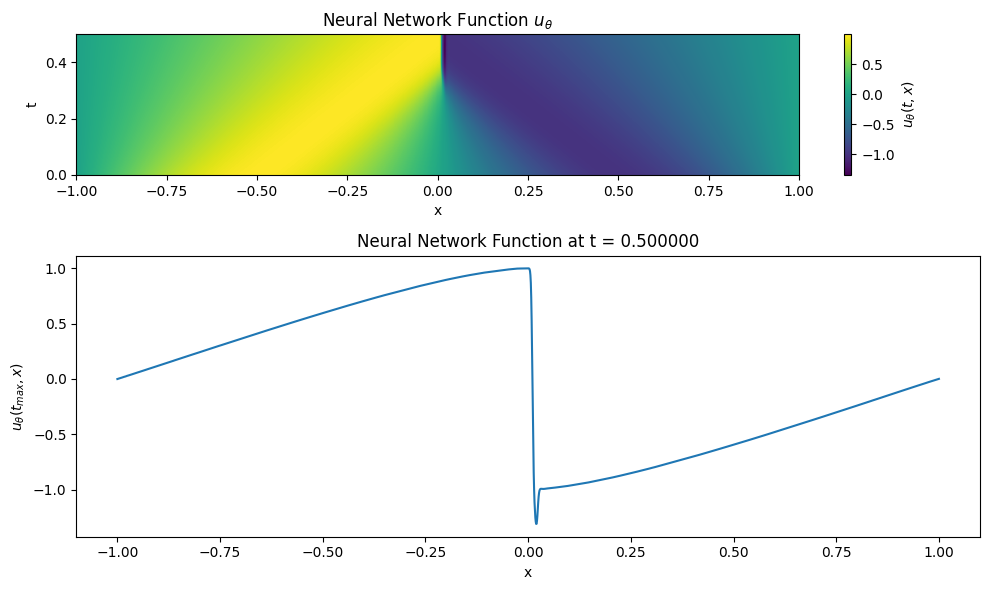

Adding grade 1 with hidden dims [64, 64, 64, 64]

Plotting before training segment [0.5000, 1.0000]


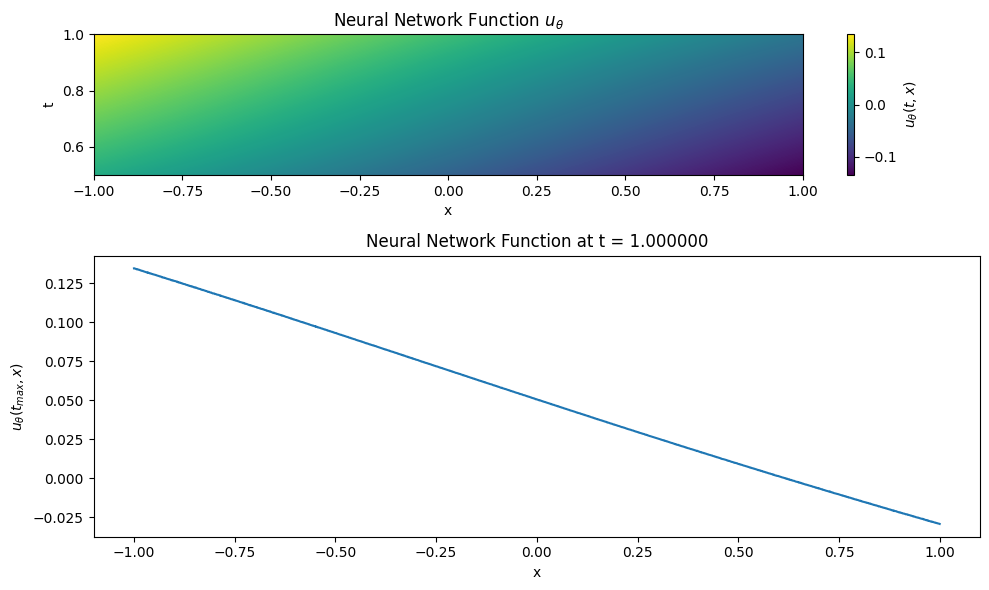


Training segment [0.5000, 1.0000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, loss_eqn: 0.204574, loss_eqn_from_kh: 0.204573, loss_eqn_abs: 0.204573, loss_ibc: 0.403934
Grade 0, Iter 100, loss_eqn: 0.533263, loss_eqn_from_kh: 0.533241, loss_eqn_abs: 0.533241, loss_ibc: 0.071674
Grade 0, Iter 200, loss_eqn: 0.362074, loss_eqn_from_kh: 0.362073, loss_eqn_abs: 0.362275, loss_ibc: 0.021846
Grade 0, Iter 300, loss_eqn: 0.307649, loss_eqn_from_kh: 0.307640, loss_eqn_abs: 0.366557, loss_ibc: 0.010986
Grade 0, Iter 400, loss_eqn: 0.210406, loss_eqn_from_kh: 0.210382, loss_eqn_abs: 0.384889, loss_ibc: 0.004316
Grade 0, Iter 500, loss_eqn: 0.127627, loss_eqn_from_kh: 0.127627, loss_eqn_abs: 0.394326, loss_ibc: 0.003175
Grade 0, Iter 600, loss_eqn: 0.123507, loss_eqn_from_kh: 0.123491, loss_eqn_abs: 0.452249, loss_ibc: 0.001790
Grade 0, Iter 700, loss_eqn: 0.081777, loss_eqn_from_kh: 0.081702, loss_eqn_abs: 0.516065, loss_ibc: 0.000785
G

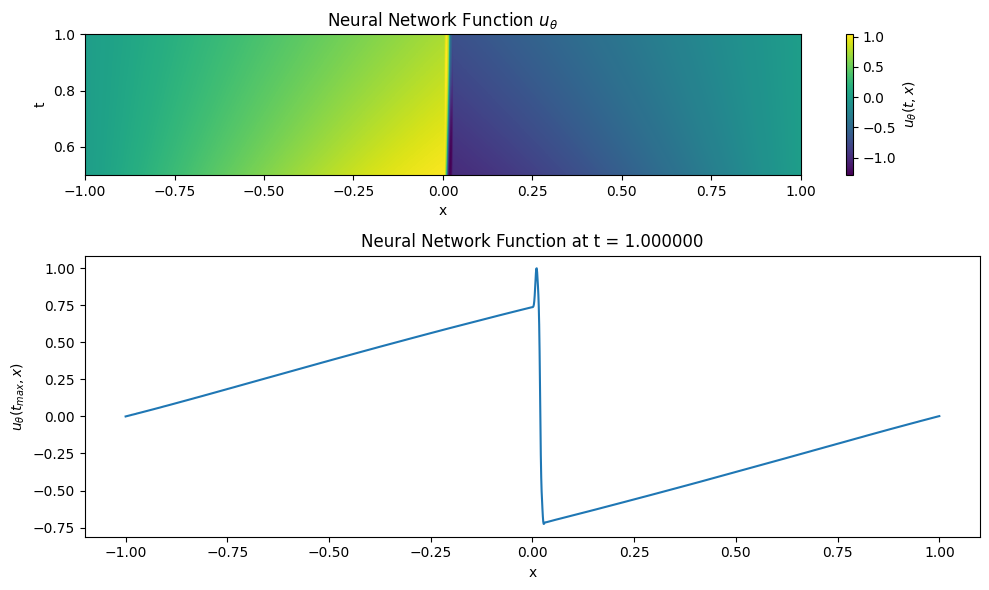


Plotting combined output across all segments from t=0 to total_t_max


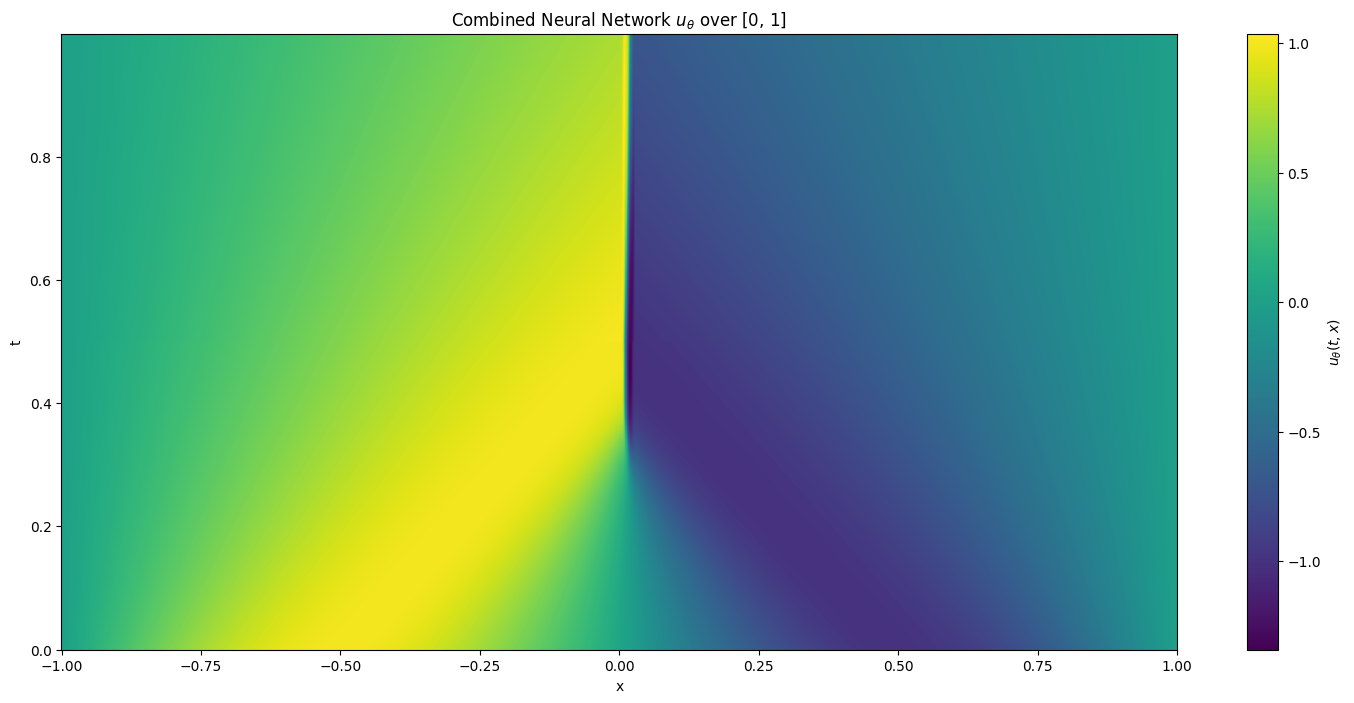

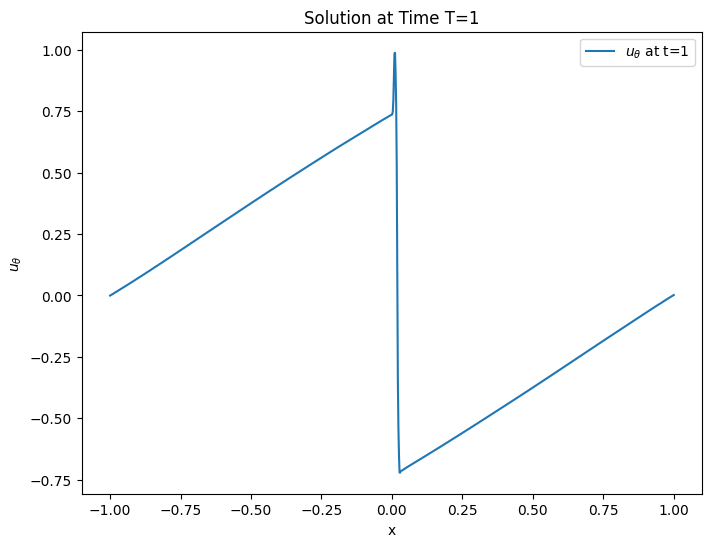

step,▁▁▂▂▂▃▃▄▄▅▅▅▆▆▆▆▇▇▇▇█▁▁▂▂▃▃▃▃▄▅▅▅▆▆▆▇▇▇█
tmin0.0_tmax0.5_loss_eqn_grade0,█▃▃▃▂▂▂▂▁▂▂▂▁▁▁▁▁▁▁▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.0_tmax0.5_loss_ibc_grade0,██▆▇▅▆▄▃▃▂▂▂▂▂▂▂▂▁▂▁▁▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_eqn_grade0,█▇▃▃▃▄▃▃▃▃▂▂▂▁▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_ibc_grade0,█▃▂▂▂▂▂▃▂▁▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,9900
tmin0.0_tmax0.5_loss_eqn_grade0,0.00282
tmin0.0_tmax0.5_loss_ibc_grade0,0.0003
tmin0.5_tmax1.0_loss_eqn_grade0,0.00131
tmin0.5_tmax1.0_loss_ibc_grade0,1e-05


In [ ]:
seq_trainer.train_seq()

Adding grade 1 with hidden dims [128, 128, 128, 128]

Plotting before training segment [0.0000, 0.5000]


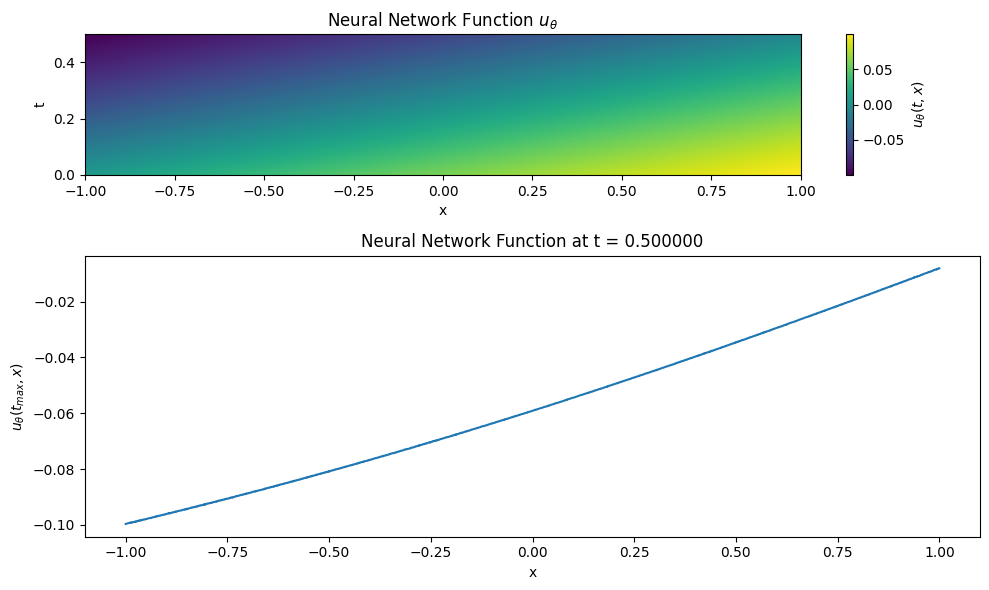


Training segment [0.0000, 0.5000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, lambda_ic: 9.730865, lambda_bc: 11.067774, lambda_eqn: 1.022727
Grade 0, Iter 0, loss_eqn: 0.228407, loss_eqn_from_kh: 0.228406, loss_eqn_abs: 0.228406, loss_ibc: 0.539963
Grade 0, Iter 100, loss_eqn: 0.118376, loss_eqn_from_kh: 0.118376, loss_eqn_abs: 0.118376, loss_ibc: 0.413318
Grade 0, Iter 200, loss_eqn: 0.444869, loss_eqn_from_kh: 0.444853, loss_eqn_abs: 0.444853, loss_ibc: 0.024301
Grade 0, Iter 300, loss_eqn: 0.331100, loss_eqn_from_kh: 0.331097, loss_eqn_abs: 0.331100, loss_ibc: 0.013102
Grade 0, Iter 400, loss_eqn: 0.251201, loss_eqn_from_kh: 0.251169, loss_eqn_abs: 0.251171, loss_ibc: 0.006061
Grade 0, Iter 500, loss_eqn: 0.205935, loss_eqn_from_kh: 0.205881, loss_eqn_abs: 0.205883, loss_ibc: 0.008408
Grade 0, Iter 600, loss_eqn: 0.177965, loss_eqn_from_kh: 0.177884, loss_eqn_abs: 0.177892, loss_ibc: 0.008008
Grade 0, Iter 700, loss_eqn: 0

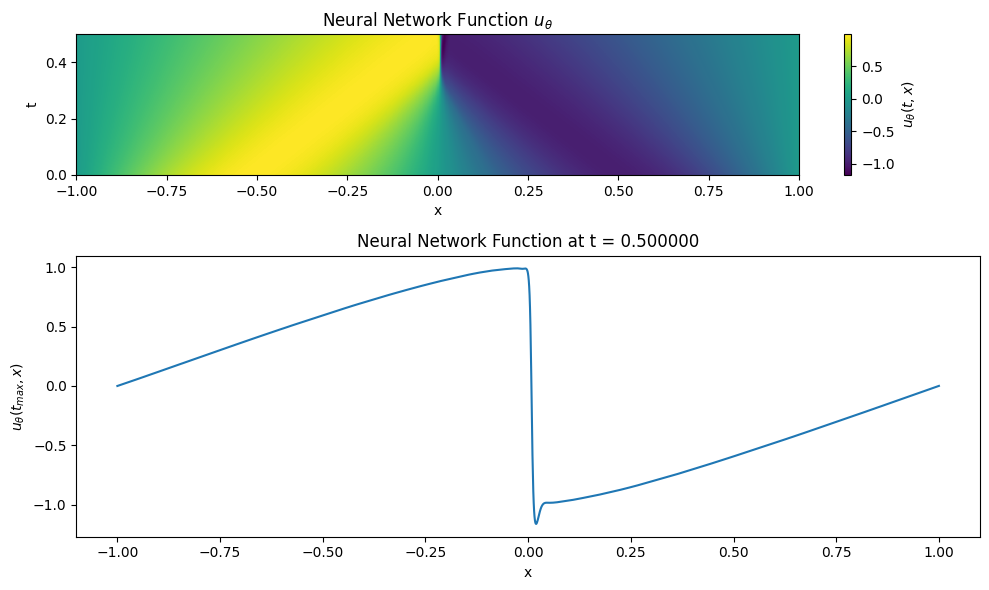

Adding grade 1 with hidden dims [128, 128, 128, 128]

Plotting before training segment [0.5000, 1.0000]


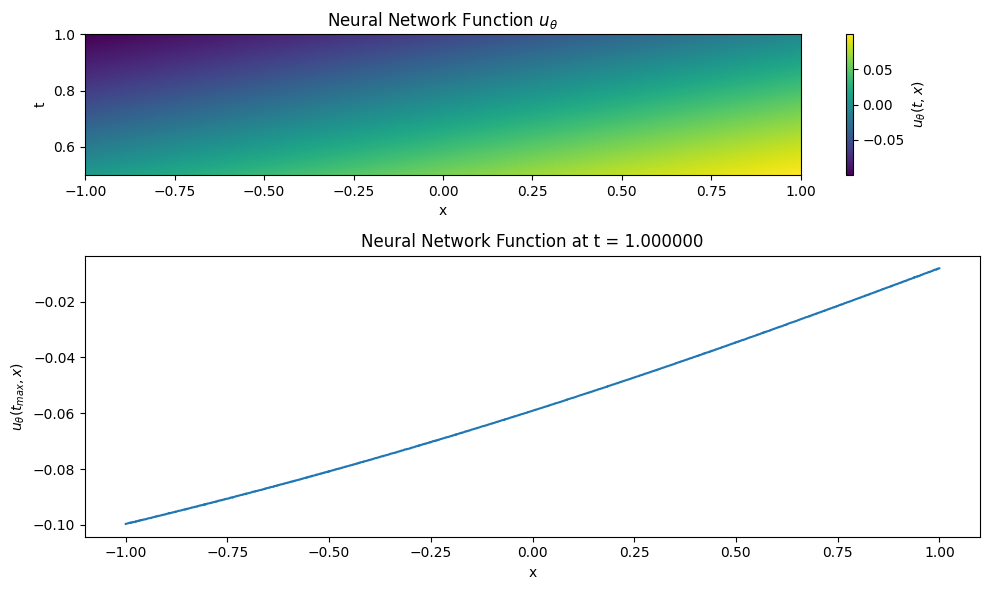


Training segment [0.5000, 1.0000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, lambda_ic: 10.052274, lambda_bc: 10.972286, lambda_eqn: 1.017060
Grade 0, Iter 0, loss_eqn: 0.228312, loss_eqn_from_kh: 0.228311, loss_eqn_abs: 0.228311, loss_ibc: 0.441596
Grade 0, Iter 100, loss_eqn: 0.042523, loss_eqn_from_kh: 0.042523, loss_eqn_abs: 0.042523, loss_ibc: 0.388595
Grade 0, Iter 200, loss_eqn: 0.397959, loss_eqn_from_kh: 0.397958, loss_eqn_abs: 0.397961, loss_ibc: 0.034705
Grade 0, Iter 300, loss_eqn: 0.372731, loss_eqn_from_kh: 0.372731, loss_eqn_abs: 0.374337, loss_ibc: 0.020366
Grade 0, Iter 400, loss_eqn: 0.318711, loss_eqn_from_kh: 0.318715, loss_eqn_abs: 0.355654, loss_ibc: 0.010995
Grade 0, Iter 500, loss_eqn: 0.249740, loss_eqn_from_kh: 0.249731, loss_eqn_abs: 0.356658, loss_ibc: 0.009161
Grade 0, Iter 600, loss_eqn: 0.160777, loss_eqn_from_kh: 0.160774, loss_eqn_abs: 0.369635, loss_ibc: 0.003030
Grade 0, Iter 700, loss_eqn: 

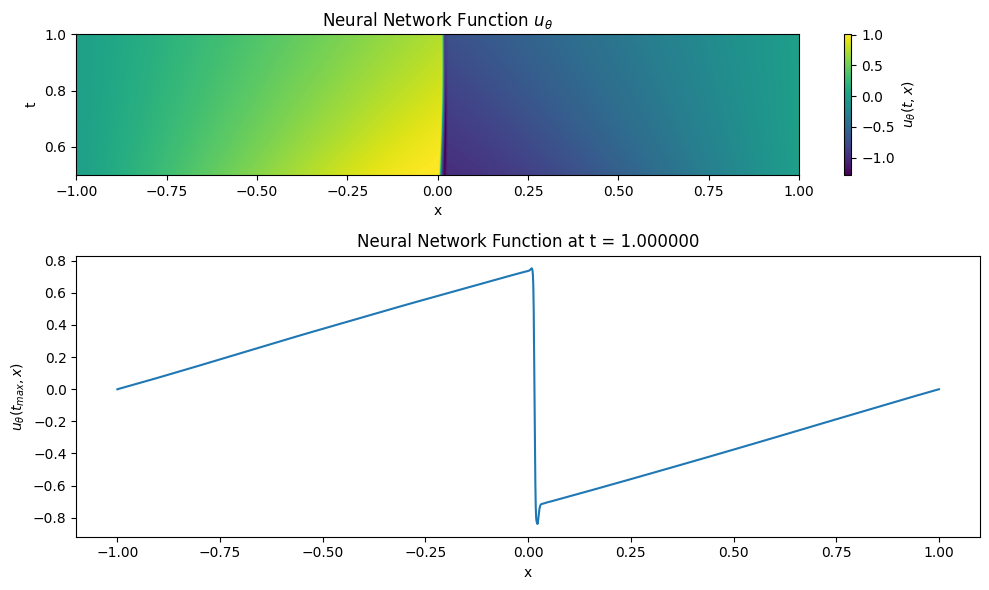


Plotting combined output across all segments from t=0 to total_t_max


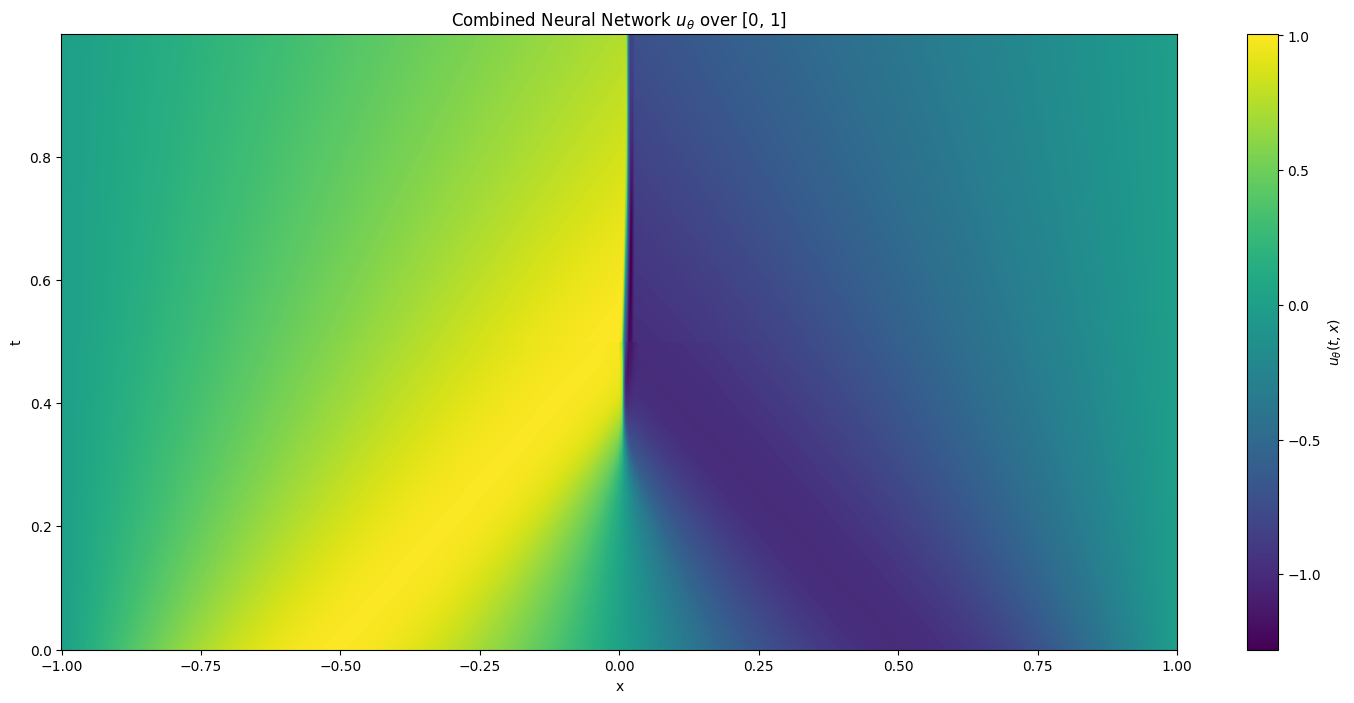

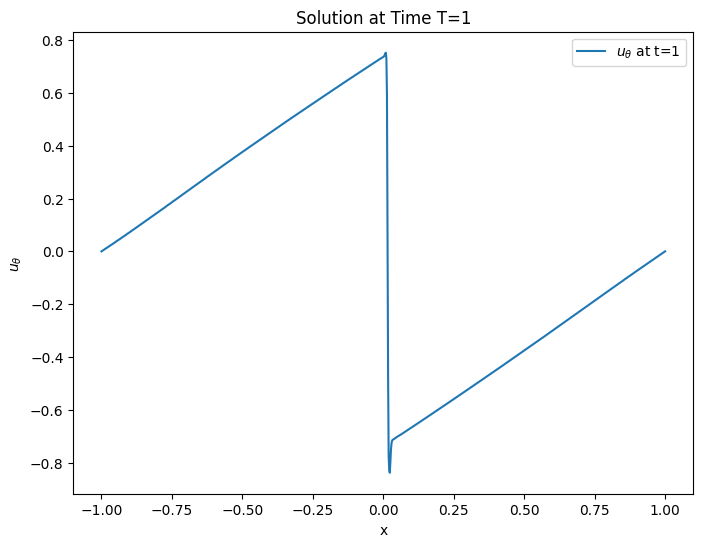

step,▁▁▂▂▂▃▃▃▃▄▄▅▅▅▅▆▇▇▇█▁▁▁▁▂▂▃▃▃▄▅▅▅▅▆▆▇▇██
tmin0.0_tmax0.5_loss_eqn_grade0,▄▃█▆▅▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.0_tmax0.5_loss_ibc_grade0,█▆▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_eqn_grade0,▅▂██▇▄▃▃▂▄▃▃▃▄▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_ibc_grade0,█▇▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,4900
tmin0.0_tmax0.5_loss_eqn_grade0,0.01869
tmin0.0_tmax0.5_loss_ibc_grade0,0.00017
tmin0.5_tmax1.0_loss_eqn_grade0,0.0059
tmin0.5_tmax1.0_loss_ibc_grade0,0.0001


In [ ]:
seq_trainer.train_seq()

In [ ]:
compute_errors_combined_u_theta(seq_trainer)

Relative error at T: 0.041117876515388604
Space-time relative error: 0.026084324864206934


(np.float64(0.041117876515388604), np.float64(0.026084324864206934))

In [ ]:
data = np.load('data/burgers_sin_ref.npz')
times = data['times']
x = data['x']
u_num = data['u']  # Shape: (n_times, n_x)

In [ ]:
times[-1]

In [ ]:
idx_T = np.argmin(np.abs(times - 1.0))

In [ ]:
idx_T

In [59]:
import jax.numpy as jnp
from jax import vmap
import numpy as np

class PiecewiseLinearPolynomialsHex:
    def __init__(self, N_t, N_x, N_y, t_min=0.0, t_max=1.0, x_min=-1.0, x_max=1.0, y_min=-1.0, y_max=1.0, gauss_order=3, bdry_order=3):
        """
        Initialize piecewise linear polynomials on a hexahedral mesh with custom ranges.

        Args:
            N_t: Number of divisions along the t-axis.
            N_x: Number of divisions along the x-axis.
            N_y: Number of divisions along the y-axis.
            t_min: Minimum value for t (default: 0.0).
            t_max: Maximum value for t (default: 1.0).
            x_min: Minimum value for x (default: -1.0).
            x_max: Maximum value for x (default: 1.0).
            y_min: Minimum value for y (default: -1.0).
            y_max: Maximum value for y (default: 1.0).
            gauss_order: Order of Gauss quadrature (number of points per direction, default: 3).
            bdry_order: Order of boundary quadrature (number of points per face direction, default: 3).
        """
        self.N_t = N_t
        self.N_x = N_x
        self.N_y = N_y
        self.t_min = t_min
        self.t_max = t_max
        self.x_min = x_min
        self.x_max = x_max
        self.y_min = y_min
        self.y_max = y_max
        self.gauss_order = gauss_order
        self.bdry_order = bdry_order
        self.N_elements = N_t * N_x * N_y  # Number of hexahedra
        self.partitions = self._generate_hexahedra()
        print(self.partitions.shape)
        self.coeffs = jnp.zeros((self.N_elements, 4))  # Coefficients a + b*t + c*x + d*y per hexahedron
        self.quad_points, self.quad_weights, self.element_indices, self.quad_points_parti, self.quad_weights_parti = self._setup_quadrature()
        # self.bdry_points_parti, self.bdry_weights_parti = self.get_boundary_quadrature()
        # self.normals = self.compute_normals()

    def _generate_hexahedra(self):
        """Generate the hexahedra for the mesh with custom ranges."""
        tau = (self.t_max - self.t_min) / self.N_t
        hx = (self.x_max - self.x_min) / self.N_x
        hy = (self.y_max - self.y_min) / self.N_y
        t_starts = jnp.linspace(self.t_min, self.t_max - tau, self.N_t)
        x_starts = jnp.linspace(self.x_min, self.x_max - hx, self.N_x)
        y_starts = jnp.linspace(self.y_min, self.y_max - hy, self.N_y)
        tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
        th, xh, yh = tl + tau, xl + hx, yl + hy
        # Define the 8 vertices for each hexahedron using binary offsets
        offsets_bin = jnp.array([[int(b) for b in f'{i:03b}'] for i in range(8)], dtype=jnp.float32)  # (8,3) binary 000 to 111
        deltas = jnp.array([tau, hx, hy])
        offsets = offsets_bin * deltas  # (8,3)
        lowers = jnp.stack([tl.ravel(), xl.ravel(), yl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 3)
        partitions = lowers + offsets[None, :, :]  # (N_elements, 8, 3)
        return partitions
        
    def _setup_quadrature(self):
        """
        Setup Gauss quadrature points and weights for hexahedral mesh.

        Returns:
            quad_points: Quadrature points, shape (N_quad, 3).
            quad_weights: Quadrature weights, shape (N_quad,).
            element_indices: Indices of hexahedra, shape (N_quad,).
            quad_points_parti: Quadrature points per hexahedron, shape (N_elements, Nq, 3).
            quad_weights_parti: Quadrature weights per hexahedron, shape (N_elements, Nq).
        """
        Nq = self.gauss_order ** 3  # Number of quadrature points per hexahedron

        # Gauss-Legendre nodes and weights in [-1, 1]
        nodes, weights = np.polynomial.legendre.leggauss(self.gauss_order)
        nodes_jnp = jnp.array(nodes)
        weights_jnp = jnp.array(weights)

        # Tensor product for 3D
        t_nodes, x_nodes, y_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp, nodes_jnp)
        t_weights, x_weights, y_weights = jnp.meshgrid(weights_jnp, weights_jnp, weights_jnp)
        quad_weights_3d = (t_weights * x_weights * y_weights).ravel()
        
        # Function to map [-1,1]^3 to hexahedron [t_low, t_high]x[x_low, x_high]x[y_low, y_high]
        def map_to_hex(hex):
            t_low, x_low, y_low = hex[0]
            t_high, x_high, y_high = hex[-1]
            t_scale = (t_high - t_low) / 2
            x_scale = (x_high - x_low) / 2
            y_scale = (y_high - y_low) / 2
            t_center = (t_high + t_low) / 2
            x_center = (x_high + x_low) / 2
            y_center = (y_high + y_low) / 2
            t_points = t_center + t_nodes.ravel() * t_scale
            x_points = x_center + x_nodes.ravel() * x_scale
            y_points = y_center + y_nodes.ravel() * y_scale
            points = jnp.stack([t_points, x_points, y_points], axis=1)
            weights = quad_weights_3d * (t_scale * x_scale * y_scale)
            return points, weights

        # Vectorize over hexahedra
        quad_points_parti, quad_weights_parti = vmap(map_to_hex)(self.partitions)
        # Flatten for global quadrature
        quad_points = quad_points_parti.reshape(-1, 3)
        quad_weights = quad_weights_parti.reshape(-1)
        element_indices = jnp.repeat(jnp.arange(self.N_elements), Nq)

        return quad_points, quad_weights, element_indices, quad_points_parti, quad_weights_parti


In [75]:
import jax.numpy as jnp
from jax import vmap
import numpy as np

# The PiecewiseLinearPolynomials class definition here (copy from previous messages)

def test_quadrature():
    # Parameters for the domain [0, 0.5] x [-1, 1] x [0, 2]
    N_t = 10  # Divisions in t
    N_x = 5  # Divisions in x
    N_y = 2  # Divisions in y
    t_min = 0.0
    t_max = 1.5
    x_min = -1.0
    x_max = 1.0
    y_min = 0.0
    y_max = 2.0
    gauss_order = 5  # For accurate quadrature

    # Instantiate the class
    pwp = PiecewiseLinearPolynomialsHex(
        N_t=N_t, N_x=N_x, N_y=N_y,
        t_min=t_min, t_max=t_max,
        x_min=x_min, x_max=x_max,
        y_min=y_min, y_max=y_max,
        gauss_order=gauss_order
    )

    # Define the function f(t, x, y) = sin(t) * x^2 + sin(t) * y^3
    def f(txy):
        t, x, y = txy
        return jnp.sin(t) * x**2 + jnp.sin(t) * y**3

    # Vectorized function evaluation
    f_vec = vmap(f)(pwp.quad_points)
    # Numerical integral = sum(f * weights)
    numerical_integral = jnp.sum(f_vec * pwp.quad_weights)

    # Analytical integral
    # ∫_0^t_max sin(t) dt = 1 - cos(t_max)
    int_sin_t = 1 - jnp.cos(t_max)
    # ∫_{-1}^1 ∫_0^2 x^2 dy dx = 2 * ∫_{-1}^1 x^2 dx = 2 * (2/3) = 4/3
    int_x2 = 4 / 3
    # ∫_{-1}^1 ∫_0^2 y^3 dy dx = ∫_{-1}^1 4 dx = 8
    int_y3 = 8
    analytical_integral = int_sin_t * (int_x2 + int_y3)

    print("Numerical Integral:", numerical_integral)
    print("Analytical Integral:", analytical_integral)
    print("Absolute Error:", jnp.abs(numerical_integral - analytical_integral))

# Run the test
test_quadrature()

(100, 8, 3)
Numerical Integral: 8.673119
Analytical Integral: 8.67312
Absolute Error: 9.536743e-07


In [76]:
N_t = 10  # Divisions in t
N_x = 5  # Divisions in x
N_y = 2  # Divisions in y
t_min = 0.0
t_max = 1.5
x_min = -1.0
x_max = 1.0
y_min = 0.0
y_max = 2.0
gauss_order = 3  # For accurate quadrature

# Instantiate the class
pwp = PiecewiseLinearPolynomialsHex(
    N_t=N_t, N_x=N_x, N_y=N_y,
    t_min=t_min, t_max=t_max,
    x_min=x_min, x_max=x_max,
    y_min=y_min, y_max=y_max,
    gauss_order=gauss_order
)

(100, 8, 3)


In [77]:
N_t = 10  # Divisions in t
N_x = 5  # Divisions in x
N_y = 2  # Divisions in y
t_min = 0.0
t_max = 1
x_min = -1.0
x_max = 1.0
y_min = 0.0
y_max = 2.0

tau = (t_max - t_min) / N_t
hx = (x_max - x_min) / N_x
hy = (y_max - y_min) / N_y
t_starts = jnp.linspace(t_min, t_max - tau, N_t)
x_starts = jnp.linspace(x_min, x_max - hx, N_x)
y_starts = jnp.linspace(y_min, y_max - hy, N_y)
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
# Define the 8 vertices for each hexahedron using binary offsets
offsets_bin = jnp.array([[int(b) for b in f'{i:03b}'] for i in range(8)], dtype=jnp.float32)  # (8,3) binary 000 to 111
deltas = jnp.array([tau, hx, hy])
offsets = offsets_bin * deltas  # (8,3)
lowers = jnp.stack([tl.ravel(), xl.ravel(), yl.ravel()], axis=1)[:, None, :]  # (N_elements, 1, 3)
partitions = lowers + offsets[None, :, :]  # (N_elements, 8, 3)

In [83]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts)
xl.shape

(5, 10, 2)

In [82]:
tl

Array([[[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9, 0.9]],

       [[0. , 0. ],
        [0.1, 0.1],
        [0.2, 0.2],
        [0.3, 0.3],
        [0.4, 0.4],
        [0.5, 0.5],
        [0.6, 0.6],
        [0.7, 0.7],
        [0.8, 0.8],
        [0.9

In [69]:
# Gauss-Legendre nodes and weights in [-1, 1]
nodes, weights = np.polynomial.legendre.leggauss(3)
nodes_jnp = jnp.array(nodes)
weights_jnp = jnp.array(weights)

# Tensor product for 3D
t_nodes, x_nodes, y_nodes = jnp.meshgrid(nodes_jnp, nodes_jnp, nodes_jnp)

In [79]:
tl, xl, yl = jnp.meshgrid(t_starts, x_starts, y_starts, indexing='ij')
tl.shape

(10, 5, 2)

In [72]:
t_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]],

       [[-0.7745967, -0.7745967, -0.7745967],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [73]:
x_nodes

Array([[[-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967],
        [-0.7745967, -0.7745967, -0.7745967]],

       [[ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       ]],

       [[ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967],
        [ 0.7745967,  0.7745967,  0.7745967]]], dtype=float32)

In [74]:
y_nodes

Array([[[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]],

       [[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]],

       [[-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967],
        [-0.7745967,  0.       ,  0.7745967]]], dtype=float32)